# Báo cáo: Nhận diện hành động người–vật (V-COCO, 6 lớp) bằng đặc trưng thủ công + ML cổ điển

Pipeline: `01_extract_features.py` → `02_train_select.py` → `03_final_test.py` → notebook này (chạy tất cả bằng `run_all.sh` ở thư mục gốc).

Notebook đọc kết quả của **một phiên bản** `results/<VERSION>/` (đặt ở ô dưới hoặc biến môi trường `RUN_VERSION`). Muốn xem phiên bản cũ thì đặt `VERSION` cũ rồi chạy lại notebook; bảng các phiên bản ở README.

- **4 đặc trưng cơ bản**: HOG (dáng người), LBP (kết cấu), Color Histogram HSV (màu/bối cảnh), SIFT + Bag of Visual Words (chi tiết cục bộ).
- **Đặc trưng bổ sung**: `geom` (hình học bbox người), `sift_spm` (BoVW + spatial pyramid 1x1+2x2), `upper` (HOG + BoVW vùng 40% phía trên: đầu/tay gần mặt), `gist` (năng lượng Gabor 4 tỉ lệ × 8 hướng trên lưới 4x4), `skin` (vị trí vùng da YCrCb).
- **Phối hợp**: `fused` (4 cơ bản), `combo_local` (sift_spm + sift_upper + color + geom + skin), `fused_all` (tất cả).
- **Mô hình**: Logistic Regression, SVM (RBF), Random Forest, XGBoost — cân bằng lớp bằng `class_weight` (XGBoost: `sample_weight`).
- **Đánh giá**: macro-F1 + recall từng lớp (không dùng accuracy vì `unknown` chiếm ~65%). Chọn mô hình trên **val**, test chỉ báo cáo.

In [1]:
import sys, json
sys.path.insert(0, '.')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, cv2, joblib
import config as C
from data_utils import load_labels, read_image
from features import hog, lbp_image, sift_descriptors, skin_mask, gabor_bank
import features as F
from models import FEATURE_SETS, blocks

import os
import versioning as V
# Phiên bản kết quả cần xem (results/<VERSION>/). Có thể truyền qua biến môi trường RUN_VERSION.
VERSION = os.environ.get('RUN_VERSION', 'r01')
RES_DIR = V.result_dir(VERSION)
FEAT_DIR = V.feat_dir(V.read_run_info(RES_DIR)['02_train_select'][0]['args']['feat_version'])
print('Kết quả:', RES_DIR.relative_to(C.ROOT), '| Đặc trưng:', FEAT_DIR.relative_to(C.ROOT))
plt.rcParams['figure.dpi'] = 100

Kết quả: results/r01 | Đặc trưng: features/f01


## 1. Khám phá dữ liệu

Cảnh báo: [all] thiếu 14668/15187 ảnh trên đĩa -> bỏ qua


split,train,val,test,train_%,val_%,test_%
label,,,,,,
hold,22,1,21,8.4,2.4,9.7
ride,8,0,3,3.1,0.0,1.4
eat/drink,18,3,10,6.9,7.1,4.6
talk_on_phone,11,1,12,4.2,2.4,5.6
work_on_computer,19,2,12,7.3,4.8,5.6
unknown,183,35,158,70.1,83.3,73.1


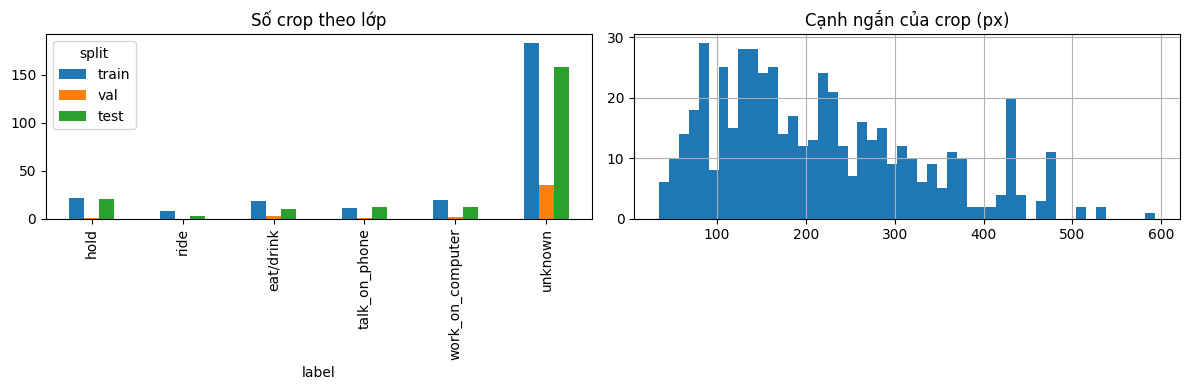

In [2]:
df = load_labels()
tab = pd.crosstab(df['label'], df['split'])[C.SPLITS].reindex(C.CLASSES)
display(tab.assign(**{f'{s}_%': (tab[s] / tab[s].sum() * 100).round(1) for s in C.SPLITS}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
tab.plot.bar(ax=axes[0]); axes[0].set_title('Số crop theo lớp')
df['short_side'] = df[['crop_w', 'crop_h']].min(axis=1)
df['short_side'].clip(upper=600).hist(bins=50, ax=axes[1]); axes[1].set_title('Cạnh ngắn của crop (px)')
plt.tight_layout()

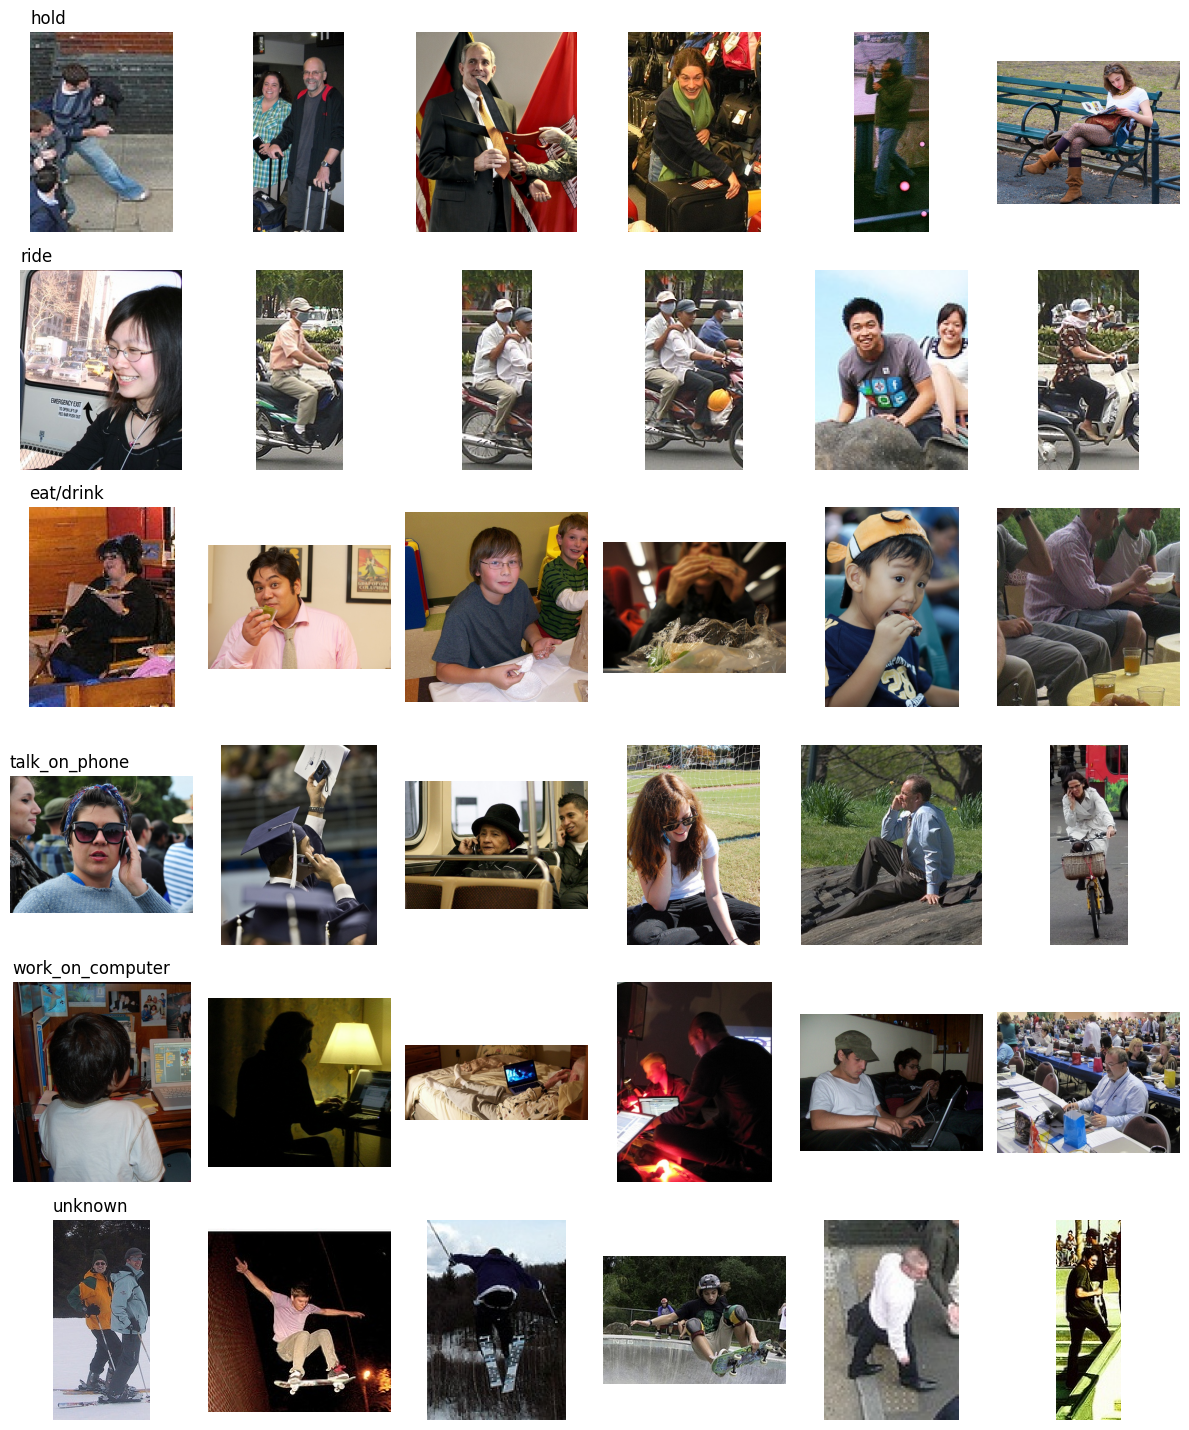

In [3]:
fig, axes = plt.subplots(len(C.CLASSES), 6, figsize=(12, 2.4 * len(C.CLASSES)))
tr = df[df.split == 'train']
for i, c in enumerate(C.CLASSES):
    sub = tr[tr.label == c].sample(min(6, (tr.label == c).sum()), random_state=0)
    for j in range(6):
        ax = axes[i, j]; ax.axis('off')
        if j < len(sub):
            ax.imshow(cv2.cvtColor(read_image(sub.iloc[j]['path']), cv2.COLOR_BGR2RGB))
        if j == 0: ax.set_title(c, loc='left')
plt.tight_layout()

## 2. Minh họa 4 loại đặc trưng

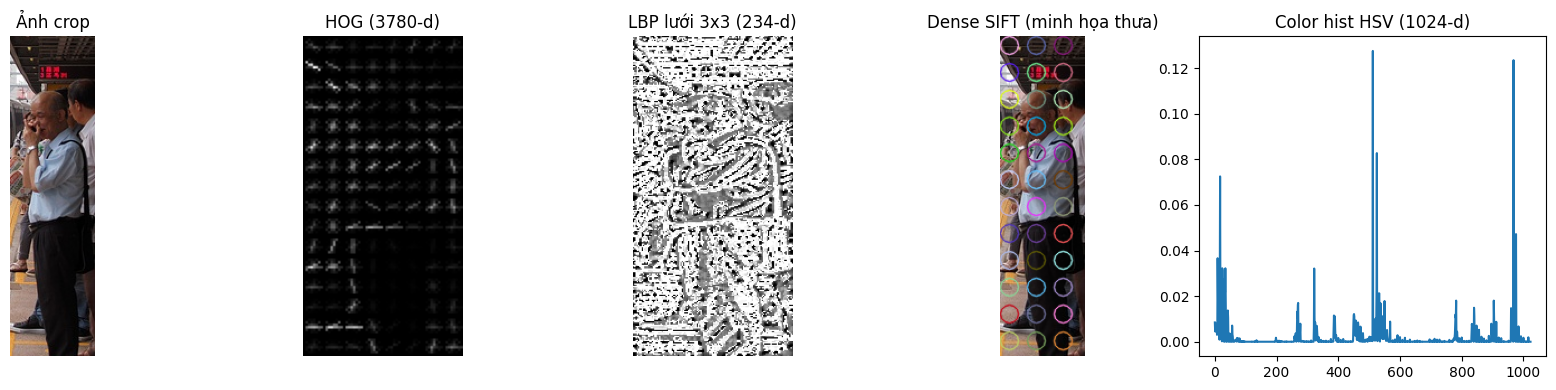

In [4]:
sample = tr[tr.label == 'talk_on_phone'].iloc[0]['path'] if (tr.label == 'talk_on_phone').any() else tr.iloc[0]['path']
img = read_image(sample)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
_, hog_img = hog(cv2.resize(gray, C.HOG_SIZE), orientations=9, pixels_per_cell=(8, 8),
                 cells_per_block=(2, 2), block_norm='L2-Hys', visualize=True)
lbp = lbp_image(img)
kps = [cv2.KeyPoint(float(x), float(y), C.SIFT_SIZE) for y in range(8, gray.shape[0] - 8, 24) for x in range(8, gray.shape[1] - 8, 24)]
sift_vis = cv2.drawKeypoints(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

fig, axes = plt.subplots(1, 5, figsize=(17, 4))
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[0].set_title('Ảnh crop')
axes[1].imshow(hog_img, cmap='gray'); axes[1].set_title(f'HOG ({len(F.hog_feat(img))}-d)')
axes[2].imshow(lbp, cmap='gray'); axes[2].set_title(f'LBP lưới 3x3 ({len(F.lbp_feat(img))}-d)')
axes[3].imshow(sift_vis); axes[3].set_title('Dense SIFT (minh họa thưa)')
axes[4].plot(F.color_feat(img)); axes[4].set_title(f'Color hist HSV ({len(F.color_feat(img))}-d)')
for a in axes[:4]: a.axis('off')
plt.tight_layout()

Các đặc trưng bổ sung: vùng thân trên, GIST (đáp ứng Gabor), skin mask, và các khối của SIFT spatial pyramid.

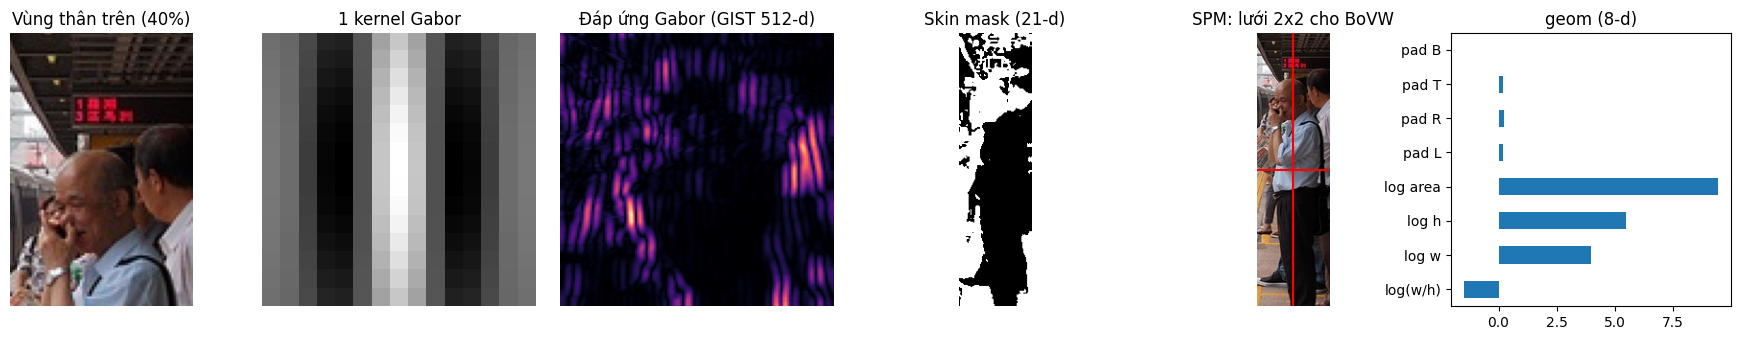

In [5]:
top = img[: int(img.shape[0] * C.UPPER_FRAC)]
g128 = cv2.resize(gray, (C.GIST_SIZE, C.GIST_SIZE)).astype(np.float32) / 255
bank = gabor_bank()
fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
axes[0].imshow(cv2.cvtColor(top, cv2.COLOR_BGR2RGB)); axes[0].set_title(f'Vùng thân trên ({C.UPPER_FRAC:.0%})')
axes[1].imshow(bank[C.GIST_ORIENT * 2], cmap='gray'); axes[1].set_title('1 kernel Gabor')
axes[2].imshow(np.abs(cv2.filter2D(g128, cv2.CV_32F, bank[C.GIST_ORIENT * 2])), cmap='magma'); axes[2].set_title(f'Đáp ứng Gabor (GIST {len(F.gist_feat(img))}-d)')
axes[3].imshow(skin_mask(img), cmap='gray'); axes[3].set_title(f'Skin mask ({len(F.skin_feat(img))}-d)')
axes[4].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[4].axhline(img.shape[0] / 2, c='r'); axes[4].axvline(img.shape[1] / 2, c='r'); axes[4].set_title('SPM: lưới 2x2 cho BoVW')
geo = pd.Series(F.geom_feat(tr[tr.path == sample].iloc[0]), index=['log(w/h)', 'log w', 'log h', 'log area', 'pad L', 'pad R', 'pad T', 'pad B'])
geo.plot.barh(ax=axes[5]); axes[5].set_title('geom (8-d)')
for a in axes[:5]: a.axis('off')
plt.tight_layout()

## 3. Kết quả chọn mô hình trên val (12 bộ đặc trưng × 4 mô hình)

,feature,model,dim,val_macro_f1,val_balanced_acc,best_params,time_s
0,sift,xgb,500,0.352102,0.366667,"{""clf__learning_rate"": 0.1, ""clf__max_depth"": ...",2.4
1,sift,svm,500,0.344679,0.416190,"{""clf__C"": 10, ""clf__gamma"": 0.0001}",0.1
2,sift,logreg,500,0.330556,0.355238,"{""clf__C"": 0.01}",0.0
3,color,svm,1024,0.328013,0.482857,"{""clf__C"": 10, ""clf__gamma"": 0.0001}",0.2
4,fused_all,logreg,10343,0.323148,0.526667,"{""clf__C"": 10}",0.7
5,upper,svm,2264,0.319444,0.355238,"{""clf__C"": 1, ""clf__gamma"": 0.0001}",0.5
6,fused,logreg,5538,0.315385,0.532381,"{""clf__C"": 10}",0.5
7,sift_spm,logreg,2500,0.295540,0.343810,"{""clf__C"": 10}",0.3
8,skin,xgb,21,0.278261,0.304762,"{""clf__learning_rate"": 0.05, ""clf__max_depth"":...",1.8
9,combo_local,logreg,4053,0.275490,0.332381,"{""clf__C"": 10}",0.3


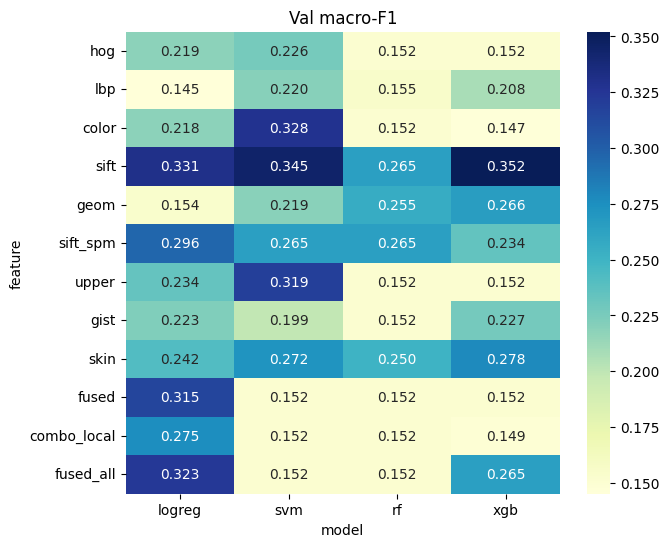

In [6]:
val = pd.read_csv(RES_DIR / 'val_results.csv')
piv = val.pivot(index='feature', columns='model', values='val_macro_f1').reindex(list(FEATURE_SETS))
piv = piv[[m for m in ['logreg', 'svm', 'rf', 'xgb'] if m in piv.columns]]
plt.figure(figsize=(7, 6)); sns.heatmap(piv, annot=True, fmt='.3f', cmap='YlGnBu'); plt.title('Val macro-F1')
display(val.sort_values('val_macro_f1', ascending=False)[['feature', 'model', 'dim', 'val_macro_f1', 'val_balanced_acc', 'best_params', 'time_s']])

Text(0.5, 1.0, 'Recall từng lớp trên val (mô hình tốt nhất cho mỗi đặc trưng)')

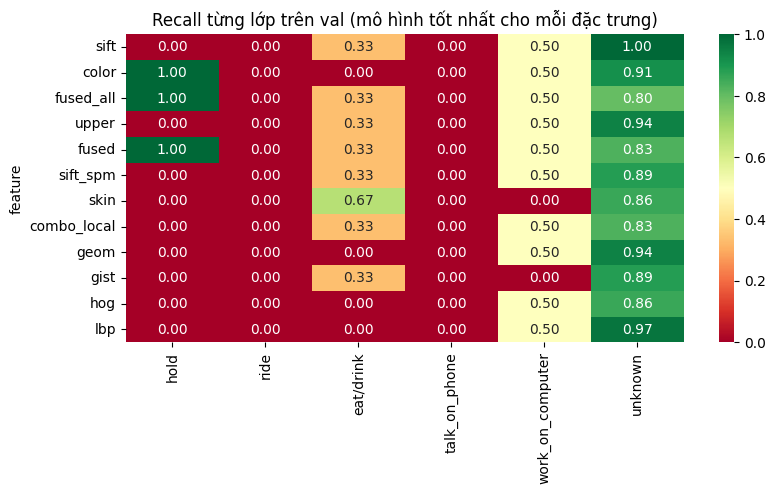

In [7]:
rec_cols = [f'recall_{c}' for c in C.CLASSES]
best_feat = val.sort_values('val_macro_f1', ascending=False).groupby('feature').head(1).set_index('feature')
plt.figure(figsize=(9, 4)); sns.heatmap(best_feat[rec_cols].rename(columns=lambda s: s[7:]), annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1)
plt.title('Recall từng lớp trên val (mô hình tốt nhất cho mỗi đặc trưng)')

## 4. Kết quả cuối trên test

In [8]:
te = pd.read_csv(RES_DIR / 'test_results.csv')
display(te[['feature', 'model', 'val_macro_f1', 'test_macro_f1', 'test_balanced_acc', 'is_best_on_val'] + rec_cols].round(4))
print((RES_DIR / 'test_report.txt').read_text())

,feature,model,val_macro_f1,test_macro_f1,test_balanced_acc,is_best_on_val,recall_hold,recall_ride,recall_eat/drink,recall_talk_on_phone,recall_work_on_computer,recall_unknown
0,sift,xgb,0.3521,0.1728,0.1785,True,0.0952,0.0,0.0,0.0000,0.0833,0.8924
1,color,svm,0.3280,0.2160,0.2222,False,0.0952,0.0,0.3,0.0000,0.0833,0.8544
2,fused_all,logreg,0.3231,0.2480,0.3062,False,0.1905,0.0,0.5,0.2500,0.3333,0.5633
3,upper,svm,0.3194,0.2444,0.2444,False,0.1429,0.0,0.2,0.0833,0.1667,0.8734
4,fused,logreg,0.3154,0.2540,0.2644,False,0.1429,0.0,0.3,0.0833,0.2500,0.8101
5,sift_spm,logreg,0.2955,0.1625,0.1662,False,0.1429,0.0,0.0,0.0000,0.0000,0.8544
6,skin,xgb,0.2783,0.2132,0.2215,False,0.0952,0.0,0.2,0.0000,0.1667,0.8671
7,combo_local,logreg,0.2755,0.2323,0.2522,False,0.1429,0.0,0.4,0.0833,0.0833,0.8038
8,geom,xgb,0.2660,0.2832,0.2789,False,0.0476,0.0,0.4,0.1667,0.1667,0.8924
9,gist,xgb,0.2269,0.1994,0.1913,False,0.0952,0.0,0.0,0.0833,0.0833,0.8861


===== sift + xgb  params={'clf__learning_rate': 0.1, 'clf__max_depth': 4, 'clf__n_estimators': 300} =====
                  precision    recall  f1-score   support

            hold     0.2000    0.0952    0.1290        21
            ride     0.0000    0.0000    0.0000         3
       eat/drink     0.0000    0.0000    0.0000        10
   talk_on_phone     0.0000    0.0000    0.0000        12
work_on_computer     0.1250    0.0833    0.1000        12
         unknown     0.7382    0.8924    0.8080       158

        accuracy                         0.6667       216
       macro avg     0.1772    0.1785    0.1728       216
    weighted avg     0.5664    0.6667    0.6092       216

===== color + svm  params={'clf__C': 10, 'clf__gamma': 0.0001} =====
                  precision    recall  f1-score   support

            hold     0.1538    0.0952    0.1176        21
            ride     0.0000    0.0000    0.0000         3
       eat/drink     0.2000    0.3000    0.2400        10
   talk_o

Text(0.5, 1.0, 'Val vs test')

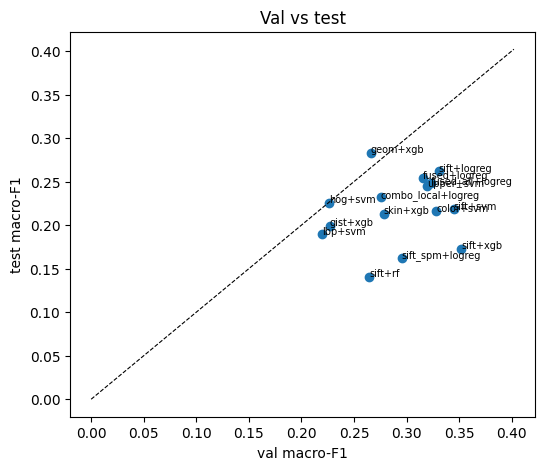

In [9]:
# Val có khớp test không? Điểm nằm xa đường chéo = chọn mô hình trên val chưa đáng tin
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(te.val_macro_f1, te.test_macro_f1)
for _, r in te.iterrows(): ax.annotate(f'{r.feature}+{r.model}', (r.val_macro_f1, r.test_macro_f1), fontsize=7)
lim = [0, max(te.val_macro_f1.max(), te.test_macro_f1.max()) + 0.05]
ax.plot(lim, lim, 'k--', lw=0.8); ax.set_xlabel('val macro-F1'); ax.set_ylabel('test macro-F1'); ax.set_title('Val vs test')

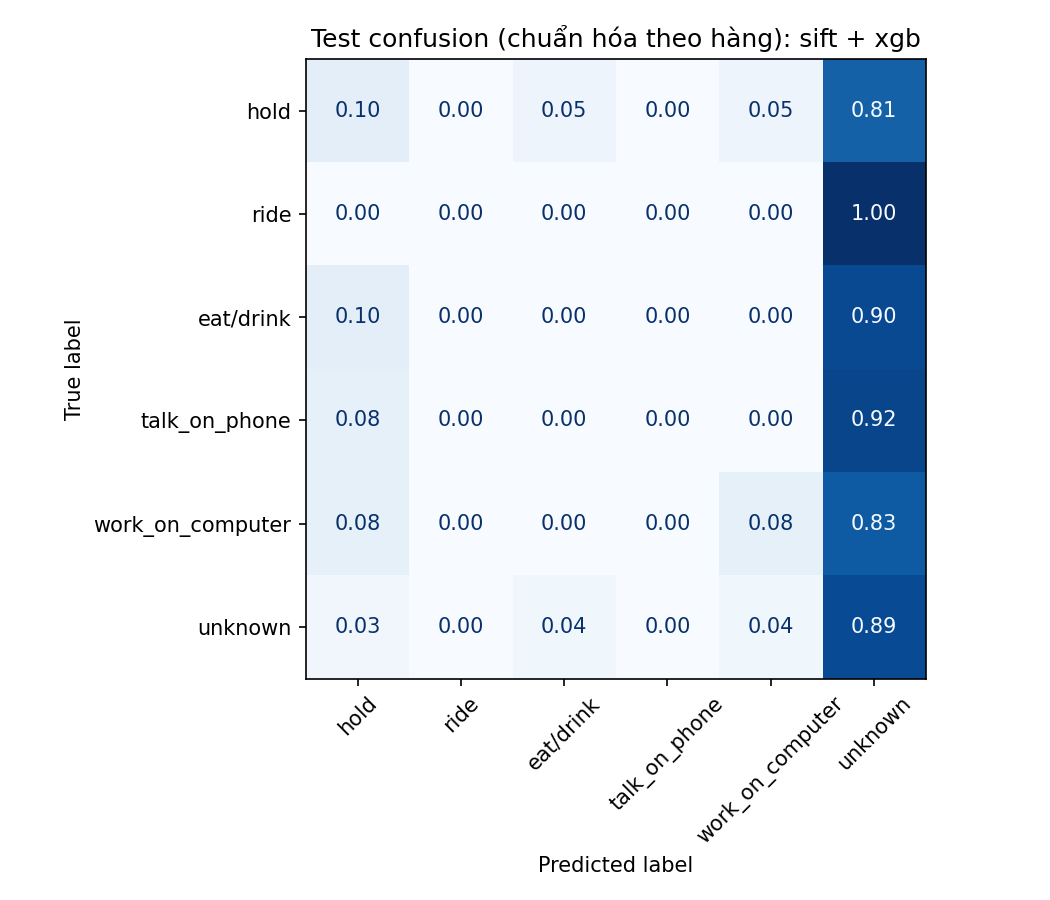

In [10]:
best = te[te.is_best_on_val].iloc[0]
from IPython.display import Image, display as d
d(Image(str(RES_DIR / f"confusion_{best.feature}_{best.model}.png"), width=550))

## 5. Thời gian chạy

Nguồn: `features/<fXX>/timing_extract.csv` (bước 1), cột thời gian trong `val_results.csv` (bước 2) và `test_results.csv` (bước 3), `run_info.json` (tổng thời gian mỗi bước).

,bước,lệnh,thời điểm,tổng thời gian (s),ghi chú
0,01_extract_features,01_extract_features.py --version f01 --note ch...,2026-10-12T22:31:18,16.3,chạy lần đầu trên 519 ảnh hiện có
1,02_train_select,02_train_select.py --feat_version f01 --versio...,2026-10-12T22:32:29,69.1,chạy lần đầu trên 519 ảnh hiện có
2,03_final_test,03_final_test.py --version r01,2026-10-12T22:32:40,9.0,


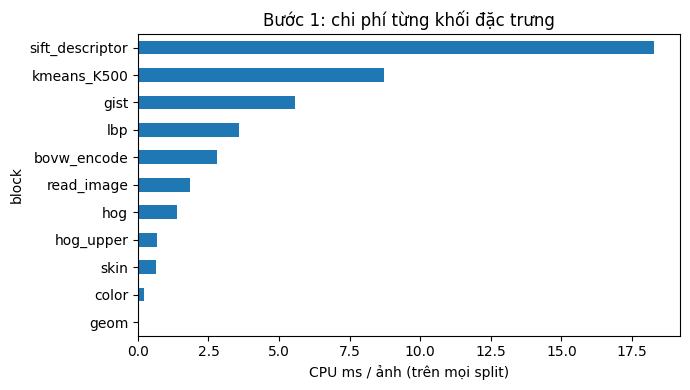

In [11]:
info = V.read_run_info(RES_DIR)
finfo = V.read_run_info(FEAT_DIR)
steps = {'01_extract_features': finfo, '02_train_select': info, '03_final_test': info}
display(pd.DataFrame([{'bước': k, 'lệnh': v[k][-1].get('command'), 'thời điểm': v[k][-1].get('time'),
                       'tổng thời gian (s)': v[k][-1].get('total_wall_s'), 'ghi chú': v[k][-1].get('note')}
                      for k, v in steps.items() if k in v]))
tx = pd.read_csv(FEAT_DIR / 'timing_extract.csv')
n_all = tx.drop_duplicates('split').n_images.sum()
blk = tx.groupby('block').cpu_s.sum().sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
(1000 * blk / n_all).plot.barh(ax=ax); ax.set_xlabel('CPU ms / ảnh (trên mọi split)')
ax.set_title('Bước 1: chi phí từng khối đặc trưng')
plt.tight_layout()

,n_grid,grid_search_s,fit_best_s
model,,,
logreg,48,2.9,0.8
rf,96,20.5,3.0
svm,108,4.3,1.0
xgb,96,18.9,17.1


,feature,model,dim,fit_s,predict_s,predict_ms_per_img
0,sift,xgb,500,1.09,0.001,0.006
1,color,svm,1024,0.03,0.045,0.208
2,fused_all,logreg,10343,0.14,0.006,0.027
3,upper,svm,2264,0.11,0.013,0.058
4,fused,logreg,5538,0.21,0.008,0.036
5,sift_spm,logreg,2500,0.06,0.004,0.017
6,skin,xgb,21,1.62,0.002,0.009
7,combo_local,logreg,4053,0.12,0.004,0.018
8,geom,xgb,8,1.72,0.002,0.010
9,gist,xgb,512,1.91,0.001,0.006


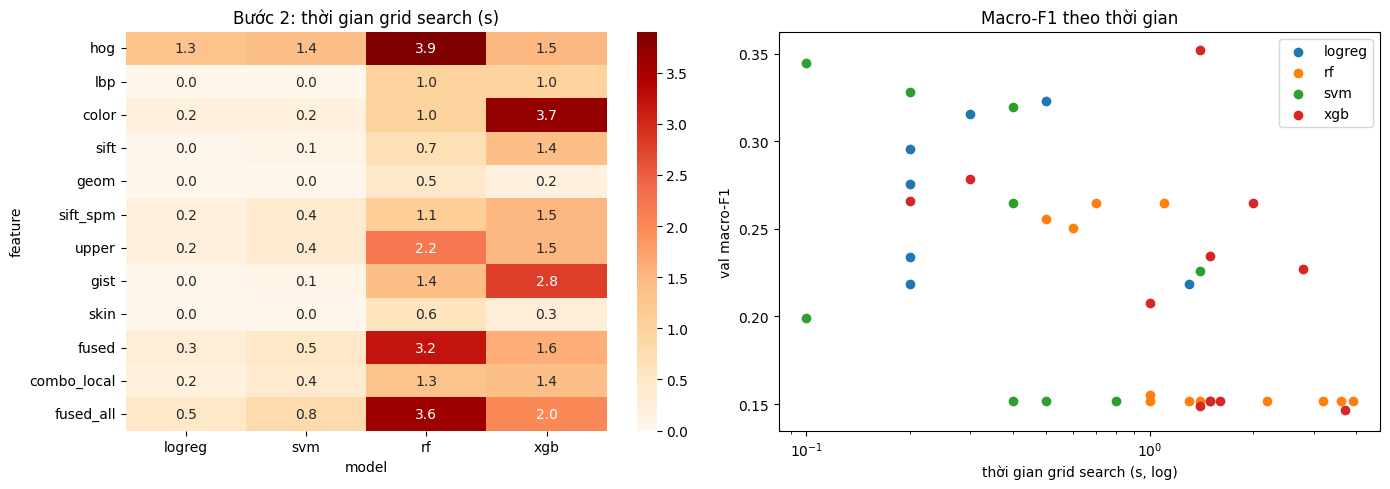

In [12]:
# Bước 2: thời gian grid search theo bộ đặc trưng x mô hình, và quan hệ macro-F1 - thời gian
if 'grid_search_s' in val:
    tp = val.pivot(index='feature', columns='model', values='grid_search_s').reindex(list(FEATURE_SETS))
    tp = tp[[m for m in ['logreg', 'svm', 'rf', 'xgb'] if m in tp.columns]]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.heatmap(tp, annot=True, fmt='.1f', cmap='OrRd', ax=axes[0]); axes[0].set_title('Bước 2: thời gian grid search (s)')
    for m, g in val.groupby('model'):
        axes[1].scatter(g.grid_search_s, g.val_macro_f1, label=m)
    axes[1].set_xscale('log'); axes[1].set_xlabel('thời gian grid search (s, log)'); axes[1].set_ylabel('val macro-F1')
    axes[1].legend(); axes[1].set_title('Macro-F1 theo thời gian')
    plt.tight_layout()
    display(val.groupby('model')[['n_grid', 'grid_search_s', 'fit_best_s']].sum().round(1))
else:
    print('Phiên bản này chưa có cột thời gian của bước 2.')
if 'fit_s' in te:
    display(te[['feature', 'model', 'dim', 'fit_s', 'predict_s', 'predict_ms_per_img']].round(3))

## 6. Phân tích lỗi

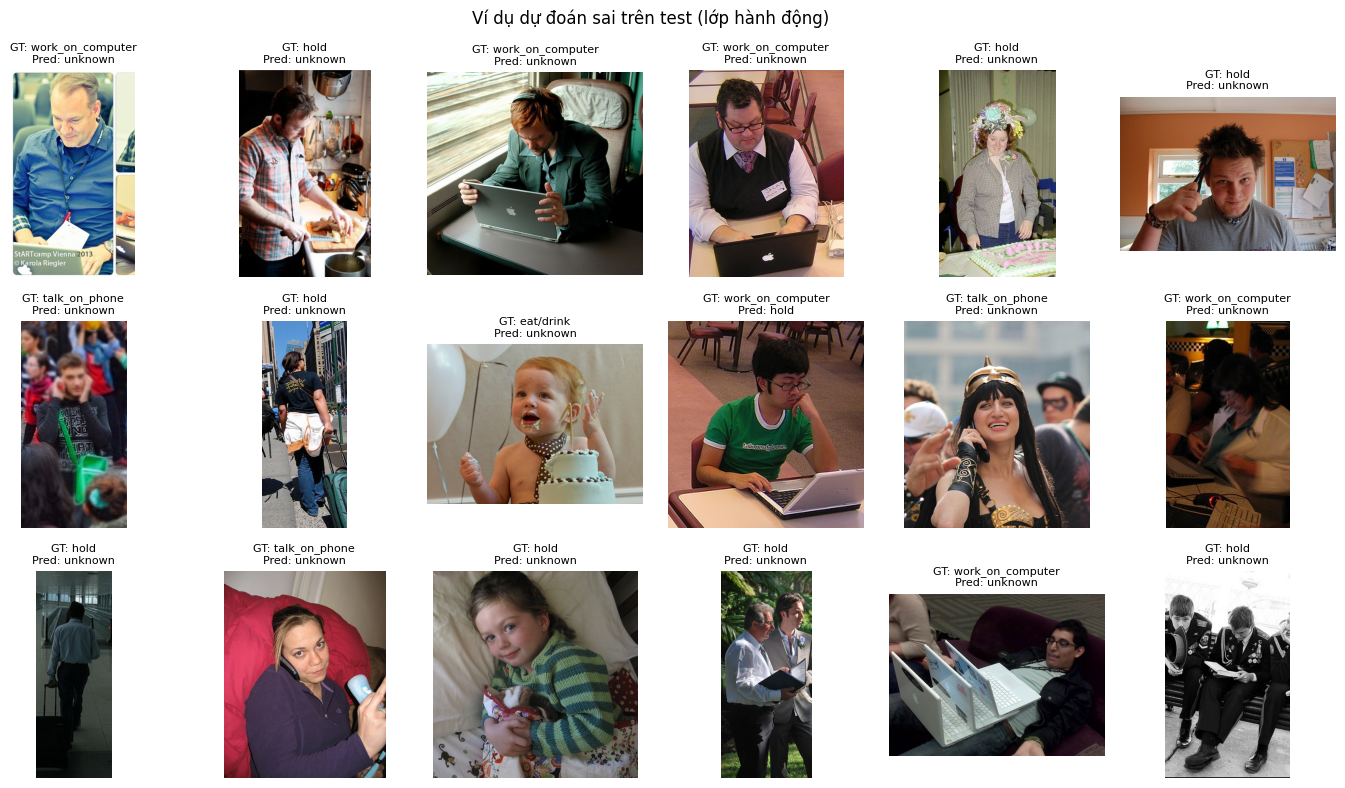

In [13]:
meta = pd.read_csv(FEAT_DIR / 'meta_test.csv')
pred = np.load(RES_DIR / f'test_pred_{best.feature}_{best.model}.npy')
meta['pred'] = [C.CLASSES[p] for p in pred]
wrong = meta[(meta.label != meta.pred) & (meta.label != 'unknown')]
fig, axes = plt.subplots(3, 6, figsize=(14, 8))
for ax, (_, r) in zip(axes.flat, wrong.sample(min(18, len(wrong)), random_state=1).iterrows()):
    ax.imshow(cv2.cvtColor(read_image(str(C.DATA_DIR / r.crop_path)), cv2.COLOR_BGR2RGB))
    ax.set_title(f'GT: {r.label}\nPred: {r.pred}', fontsize=8)
for ax in axes.flat: ax.axis('off')
plt.suptitle('Ví dụ dự đoán sai trên test (lớp hành động)'); plt.tight_layout()

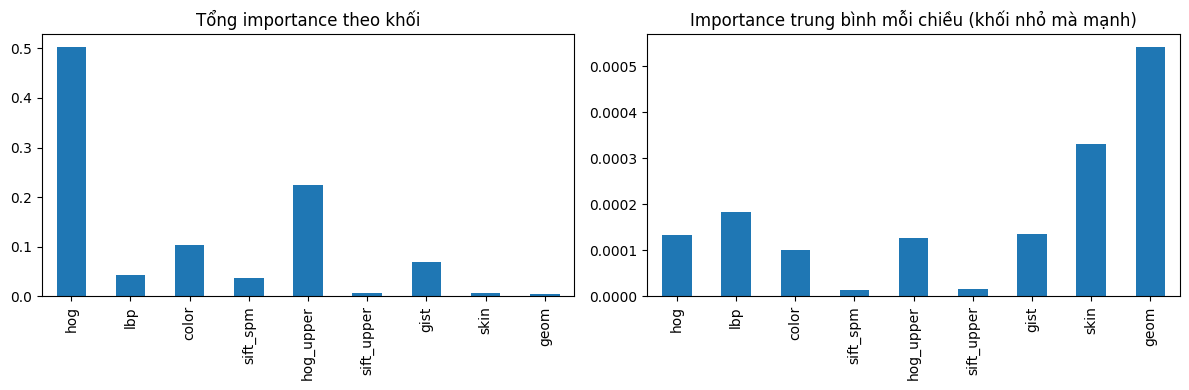

In [14]:
# Độ quan trọng theo khối đặc trưng: RF (không PCA) train trên train, bộ fused_all
from sklearn.ensemble import RandomForestClassifier
from models import load_xy
Xtr, ytr = load_xy(FEAT_DIR, 'train', 'fused_all')
rf = RandomForestClassifier(500, class_weight='balanced_subsample', n_jobs=-1, random_state=C.SEED).fit(Xtr, ytr)
bl = blocks('fused_all')
dims = [np.load(FEAT_DIR / f'train_{b}.npy', mmap_mode='r').shape[1] for b in bl]
imp = np.split(rf.feature_importances_, np.cumsum(dims)[:-1])
imp_df = pd.DataFrame({'tổng': [v.sum() for v in imp], 'trung bình / chiều': [v.mean() for v in imp]}, index=bl)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
imp_df['tổng'].plot.bar(ax=axes[0], title='Tổng importance theo khối')
imp_df['trung bình / chiều'].plot.bar(ax=axes[1], title='Importance trung bình mỗi chiều (khối nhỏ mà mạnh)')
plt.tight_layout()

## 7. Nhận xét gợi ý
- `ride`: crop chỉ chứa ~47% diện tích vật (ngựa/xe) → cần bối cảnh (`gist`, `color`) và dáng ngồi (`geom`, HOG).
- `talk_on_phone`, `eat/drink`: vật nhỏ ở gần đầu → `upper` và `sift_spm` được thiết kế cho trường hợp này.
- `geom` chỉ 8 chiều nhưng mang thông tin tỉ lệ khung/vị trí mà các đặc trưng ảnh (đã resize) làm mất.
- Mọi lựa chọn siêu tham số dựa trên val; test chỉ được dùng để báo cáo. Nếu val nhỏ, biểu đồ val-vs-test cho thấy việc chọn mô hình còn nhiễu.